In [1]:

# 1. Importer les bibliothèques
from sklearn.datasets import load_digits
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt




In [2]:
from tensorflow.keras.datasets import mnist

# Charger le dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normaliser les pixels entre 0 et 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Transformer chaque image 28x28 en vecteur de 784 pixels
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("Minimum :", X_train.min())
print("Maximum :", X_train.max())

X_train : (60000, 784)
X_test : (10000, 784)
Minimum : 0.0
Maximum : 1.0


In [3]:
# 3. Normaliser les pixels
X = X / 255.0

print("Pixel minimum :", X.min())
print("Pixel maximum :", X.max())
# 4. Diviser les données : 80% entraînement, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



NameError: name 'X' is not defined

In [ ]:
# 5. Créer le modèle MLP
model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=30,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=5
)

# 6. Entraîner le modèle
model.fit(X_train, y_train)

# 7. Prédire les chiffres
y_pred = model.predict(X_test)



In [ ]:
# 8. Calculer les métriques
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 9. Afficher les résultats
print("\n--- Métriques de performance ---")
print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-score  :", round(f1, 4))




--- Métriques de performance ---
Accuracy  : 0.9806
Precision : 0.981
Recall    : 0.9806
F1-score  : 0.9806


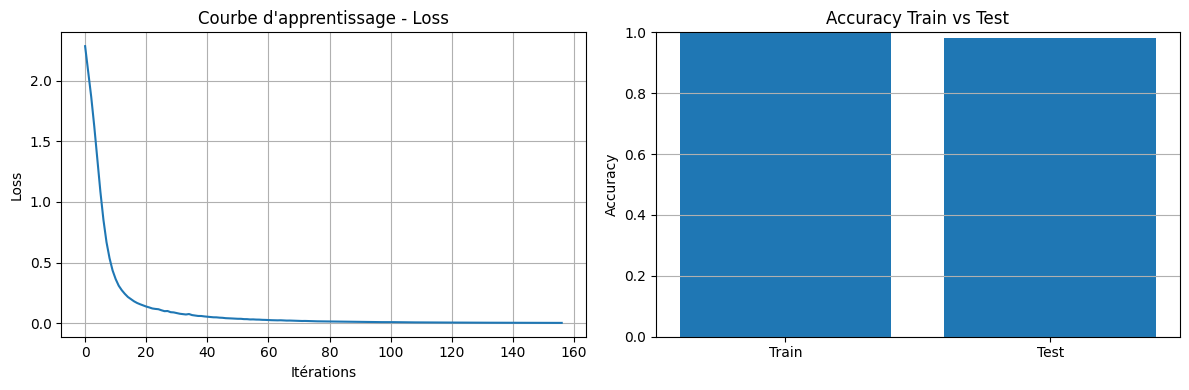

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Courbe de la fonction de perte
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(model.loss_curve_)
plt.title("Courbe d'apprentissage - Loss")
plt.xlabel("Itérations")
plt.ylabel("Loss")
plt.grid(True)

# Comparaison des accuracies
acc_train = accuracy_score(y_train, model.predict(X_train))
acc_test = accuracy_score(y_test, model.predict(X_test))

plt.subplot(1, 2, 2)
plt.bar(
    ["Train", "Test"],
    [acc_train, acc_test]
)
plt.title("Accuracy Train vs Test")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")

plt.tight_layout()
plt.show()


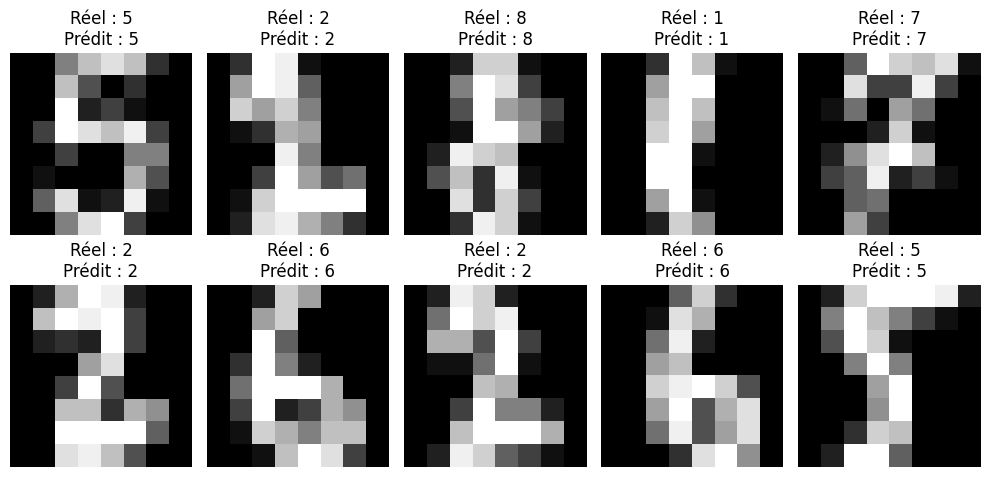

In [ ]:
# 10. Afficher quelques images et prédictions
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    image = X_test[i].reshape(8, 8)
    plt.imshow(image, cmap="gray")

    plt.title(
        f"Réel : {y_test[i]}\nPrédit : {y_pred[i]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:

# ==================================================
# 1. IMPORTATION DES BIBLIOTHEQUES
# ==================================================
from tensorflow.keras.datasets import mnist

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# ==================================================
# 2. CHARGEMENT DU DATASET MNIST
# ==================================================
print("Chargement du dataset MNIST...")

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dimensions originales de X_train :", X_train.shape)
print("Dimensions originales de X_test  :", X_test.shape)

# ==================================================
# 3. NORMALISATION DES PIXELS
# ==================================================
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("\nMinimum des pixels :", X_train.min())
print("Maximum des pixels :", X_train.max())

# ==================================================
# 4. TRANSFORMATION DES IMAGES EN VECTEURS
# ==================================================
# Chaque image 28 x 28 devient un vecteur de 784 valeurs

X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

print("\nDimensions finales :")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)



Chargement du dataset MNIST...
Dimensions originales de X_train : (60000, 28, 28)
Dimensions originales de X_test  : (10000, 28, 28)

Minimum des pixels : 0.0
Maximum des pixels : 1.0

Dimensions finales :
X_train : (60000, 784)
X_test  : (10000, 784)
y_train : (60000,)
y_test  : (10000,)


In [ ]:
# ==================================================
# 5. CREATION DU MODELE MLP
# ==================================================
model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=30,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=5,
    verbose=True
)

# ==================================================
# 6. ENTRAINEMENT DU MODELE
# ==================================================
print("\nEntrainement du modele...")

model.fit(X_train, y_train)

print("\nEntrainement termine !")
print("Nombre d'iterations :", model.n_iter_)



Entrainement du modele...
Iteration 1, loss = 0.40444702
Validation score: 0.939167
Iteration 2, loss = 0.16155769
Validation score: 0.959167
Iteration 3, loss = 0.11461625
Validation score: 0.964833
Iteration 4, loss = 0.08749172
Validation score: 0.965167
Iteration 5, loss = 0.07013413
Validation score: 0.970667
Iteration 6, loss = 0.05688627
Validation score: 0.971167
Iteration 7, loss = 0.04671184
Validation score: 0.971833
Iteration 8, loss = 0.03684388
Validation score: 0.974833
Iteration 9, loss = 0.03002249
Validation score: 0.973167
Iteration 10, loss = 0.02725657
Validation score: 0.974167
Iteration 11, loss = 0.02233115
Validation score: 0.975500
Iteration 12, loss = 0.01825737
Validation score: 0.976667
Iteration 13, loss = 0.01651127
Validation score: 0.972667
Iteration 14, loss = 0.01425605
Validation score: 0.976667
Iteration 15, loss = 0.01027408
Validation score: 0.977000
Iteration 16, loss = 0.00857696
Validation score: 0.978000
Iteration 17, loss = 0.00669776
Valida

In [ ]:

# ==================================================
# 7. PREDICTIONS
# ==================================================
y_pred = model.predict(X_test)


In [ ]:

# ==================================================
# 8. EVALUATION DU MODELE
# ==================================================
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print("\n========== RESULTATS ==========")
print("Accuracy  :", round(accuracy, 4))
print("Precision :", round(precision, 4))
print("Recall    :", round(recall, 4))
print("F1-score  :", round(f1, 4))

print("\n========== RAPPORT DE CLASSIFICATION ==========")
print(classification_report(y_test, y_pred, zero_division=0))




========== RESULTATS ==========
Accuracy  : 0.9779
Precision : 0.978
Recall    : 0.9779
F1-score  : 0.9779

========== RAPPORT DE CLASSIFICATION ==========
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.97      1032
           3       0.96      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.99      0.97      0.98       958
           7       0.98      0.98      0.98      1028
           8       0.98      0.96      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



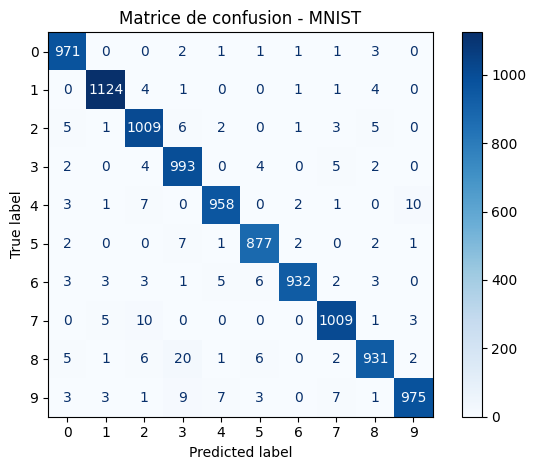

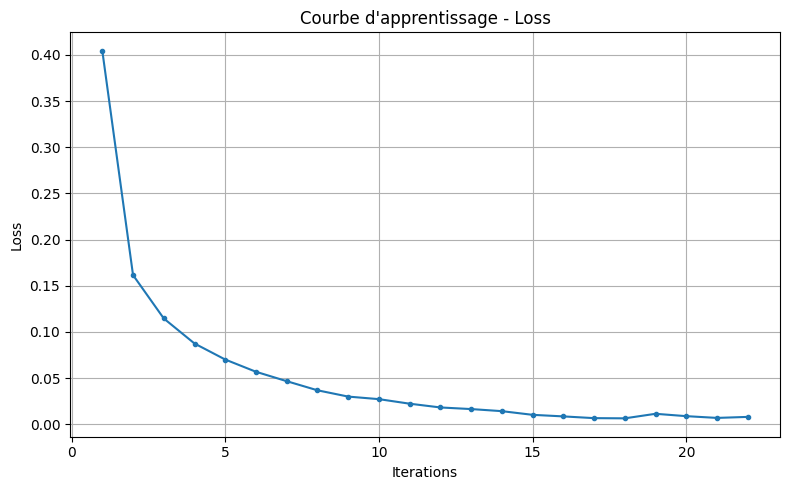

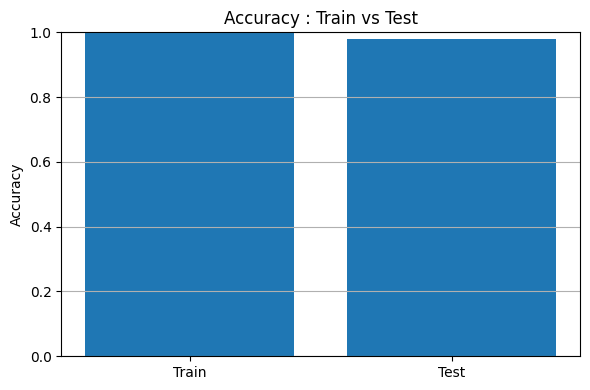

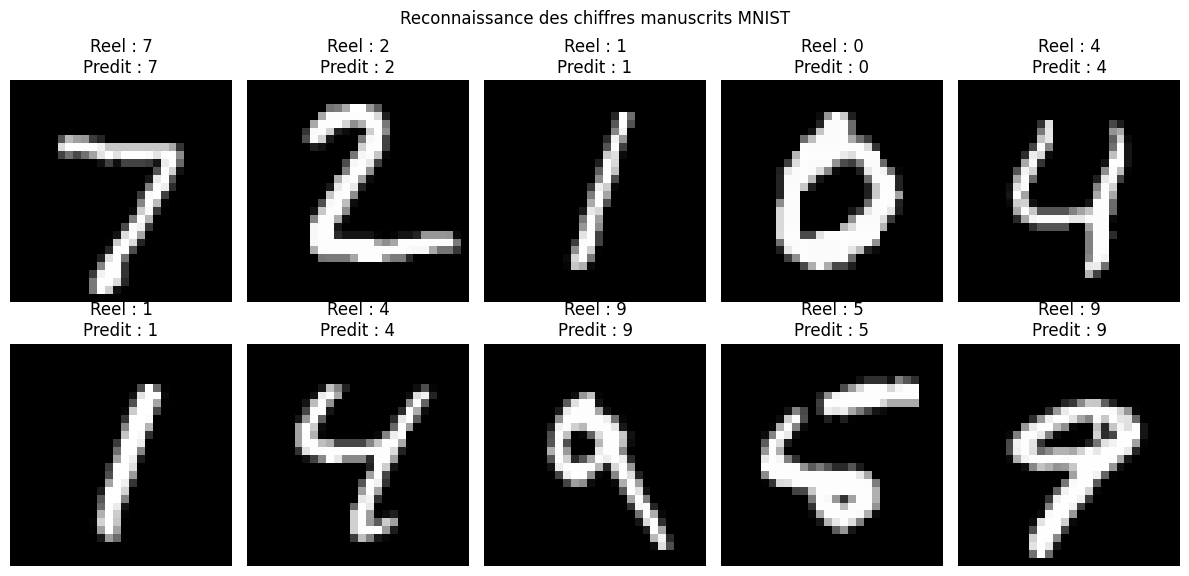

In [ ]:
# ==================================================
# 9. MATRICE DE CONFUSION
# ==================================================
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - MNIST")
plt.tight_layout()
plt.show()

# ==================================================
# 10. COURBE DE LOSS
# ==================================================
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(model.loss_curve_) + 1),
    model.loss_curve_,
    marker="o",
    markersize=3
)

plt.title("Courbe d'apprentissage - Loss")
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

# ==================================================
# 11. ACCURACY TRAIN VS TEST
# ==================================================
acc_train = accuracy_score(
    y_train,
    model.predict(X_train)
)

acc_test = accuracy_score(y_test, y_pred)

plt.figure(figsize=(6, 4))

plt.bar(
    ["Train", "Test"],
    [acc_train, acc_test]
)

plt.title("Accuracy : Train vs Test")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ==================================================
# 12. AFFICHAGE DE 10 IMAGES ET PREDICTIONS
# ==================================================
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Restructurer le vecteur en image 28 x 28
    image = X_test[i].reshape(28, 28)

    plt.imshow(image, cmap="gray")

    plt.title(
        f"Reel : {y_test[i]}\nPredit : {y_pred[i]}"
    )

    plt.axis("off")

plt.suptitle("Reconnaissance des chiffres manuscrits MNIST")
plt.tight_layout()
plt.show()


In [ ]:

# 1. Importation des bibliothèques
from tensorflow.keras.datasets import mnist

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# 2. Chargement de MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

# 3. Normalisation des pixels : [0, 255] -> [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# 4. Aplatir les images 28x28 en vecteurs de 784 valeurs
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

print("Après transformation :", X_train.shape)

# 5. Création du réseau : 784 -> 128 -> 64 -> 10
model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=30,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=5,
    verbose=True
)

# 6. Entraînement
model.fit(X_train, y_train)

# 7. Prédictions
y_pred = model.predict(X_test)


X_train : (60000, 28, 28)
X_test  : (10000, 28, 28)
Après transformation : (60000, 784)
Iteration 1, loss = 0.40444702
Validation score: 0.939167
Iteration 2, loss = 0.16155769
Validation score: 0.959167
Iteration 3, loss = 0.11461625
Validation score: 0.964833
Iteration 4, loss = 0.08749172
Validation score: 0.965167
Iteration 5, loss = 0.07013413
Validation score: 0.970667
Iteration 6, loss = 0.05688627
Validation score: 0.971167
Iteration 7, loss = 0.04671184
Validation score: 0.971833
Iteration 8, loss = 0.03684388
Validation score: 0.974833
Iteration 9, loss = 0.03002249
Validation score: 0.973167
Iteration 10, loss = 0.02725657
Validation score: 0.974167
Iteration 11, loss = 0.02233115
Validation score: 0.975500
Iteration 12, loss = 0.01825737
Validation score: 0.976667
Iteration 13, loss = 0.01651127
Validation score: 0.972667
Iteration 14, loss = 0.01425605
Validation score: 0.976667
Iteration 15, loss = 0.01027408
Validation score: 0.977000
Iteration 16, loss = 0.00857696
Vali

In [ ]:

# 8. Métriques
print("\n===== ÉVALUATION =====")

print("Accuracy  :", round(
    accuracy_score(y_test, y_pred), 4
))

print("Precision :", round(
    precision_score(
        y_test, y_pred,
        average="weighted", zero_division=0
    ), 4
))

print("Recall    :", round(
    recall_score(
        y_test, y_pred,
        average="weighted", zero_division=0
    ), 4
))

print("F1-score  :", round(
    f1_score(
        y_test, y_pred,
        average="weighted", zero_division=0
    ), 4
))




===== ÉVALUATION =====
Accuracy  : 0.9779
Precision : 0.978
Recall    : 0.9779
F1-score  : 0.9779


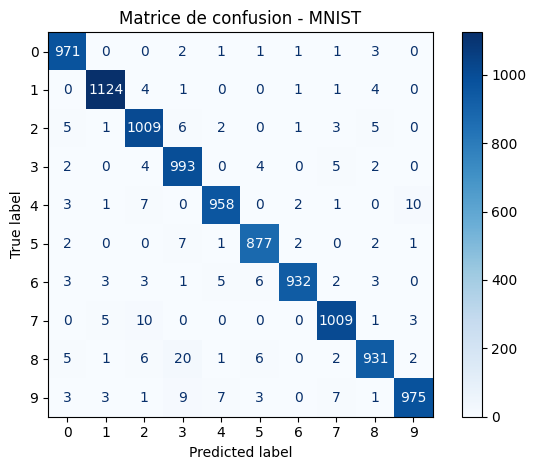

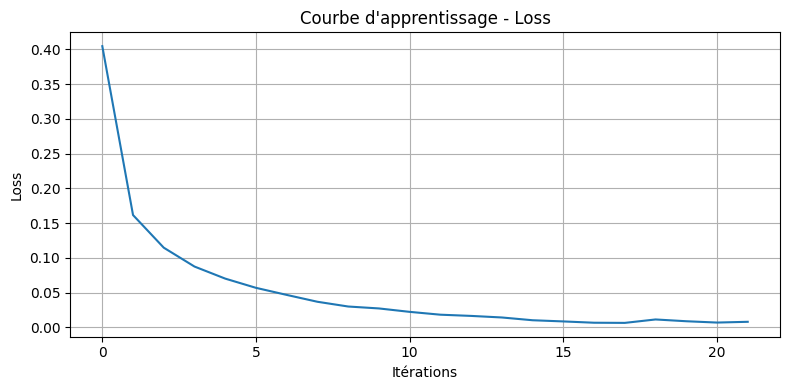

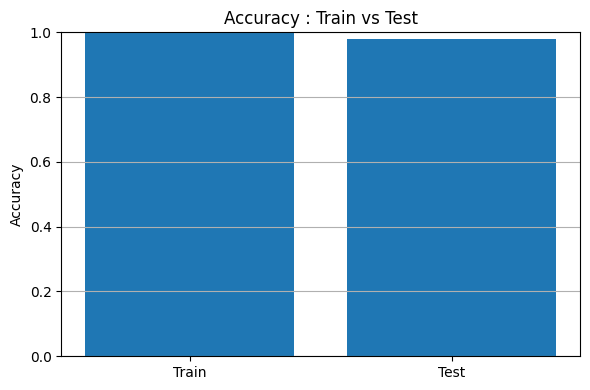

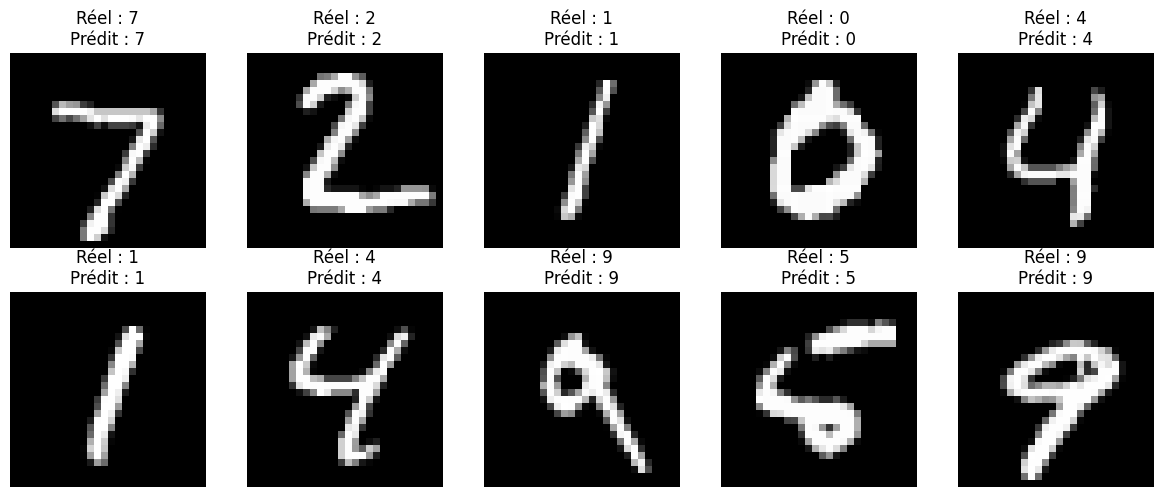

In [ ]:
# 9. Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
).plot(cmap="Blues", values_format="d")

plt.title("Matrice de confusion - MNIST")
plt.tight_layout()
plt.show()

# 10. Courbe de perte
plt.figure(figsize=(8, 4))
plt.plot(model.loss_curve_)
plt.title("Courbe d'apprentissage - Loss")
plt.xlabel("Itérations")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

# 11. Accuracy sur Train et Test
acc_train = accuracy_score(
    y_train, model.predict(X_train)
)
acc_test = accuracy_score(y_test, y_pred)

plt.figure(figsize=(6, 4))
plt.bar(["Train", "Test"], [acc_train, acc_test])
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Accuracy : Train vs Test")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# 12. Afficher 10 prédictions
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Réel : {y_test[i]}\nPrédit : {y_pred[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
w